# Predicting Airline Satisfaction
### 04 · Modelo final, visualizaciones y entrega a Kaggle

**Competencia:** [Kaggle · Playground Series S6E10](https://www.kaggle.com/competitions/playground-series-s6e10/overview)  
**Problema:** clasificación binaria de la satisfacción de pasajeros.  
**Métrica principal:** ROC-AUC.  
**Modelo seleccionado:** Random Forest optimizado mediante `RandomizedSearchCV` en `03_modelado.ipynb`.

En este notebook evaluamos visualmente la configuración ganadora, entrenamos el modelo final con todos los registros etiquetados y generamos el archivo `submission.csv`. También exportamos **dos figuras** para mostrar el proyecto en GitHub o LinkedIn.

## Guía de lectura

1. **Carga y comprobaciones:** revisar `train.csv` y `test.csv`.
2. **Pipeline definitivo:** imputación, One-Hot Encoding y Random Forest optimizado.
3. **Curva ROC:** entrenar una copia del Pipeline con 80 % de los datos y evaluar sobre el 20 % restante **sin usarlo en el ajuste**.
4. **Entrenamiento final:** reajustar el modelo con el 100 % de los registros etiquetados.
5. **Árbol representativo:** visualizar las primeras capas de uno de los 100 árboles del bosque.
6. **Predicciones y entrega:** calcular probabilidades y guardar `submission.csv`.

> **Precisión metodológica:** la curva ROC corresponde al **modelo de evaluación entrenado con 80 % de los datos**. El modelo final utilizado en Kaggle se vuelve a entrenar con el 100 % de `train.csv`; su rendimiento sobre `test.csv` solo puede conocerse después de que Kaggle evalúe la entrega. No calculamos ROC-AUC sobre el mismo conjunto usado para entrenar el modelo final.

## 1. Cargar los datos

Utilizamos las mismas columnas y los mismos hiperparámetros seleccionados en el notebook anterior. Detectamos la carpeta raíz del proyecto para que las rutas funcionen al ejecutar Jupyter desde `notebooks/` o desde la raíz del repositorio.

In [1]:
from pathlib import Path
import gc

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.metrics import roc_auc_score, roc_curve
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.tree import plot_tree

proyecto = next(
    (ruta for ruta in [Path.cwd(), *Path.cwd().parents]
     if (ruta / "data" / "train.csv").is_file()
     and (ruta / "data" / "test.csv").is_file()),
    None,
)
if proyecto is None:
    raise FileNotFoundError(
        "No encuentro data/train.csv y data/test.csv. Abre el proyecto "
        "desde su carpeta principal o desde notebooks/."
    )

carpeta_imagenes = proyecto / "images"
carpeta_imagenes.mkdir(parents=True, exist_ok=True)

train_final = pd.read_csv(proyecto / "data" / "train.csv")
test_final = pd.read_csv(proyecto / "data" / "test.csv")

print("Train:", train_final.shape)
print("Test:", test_final.shape)
print("Carpeta de figuras:", carpeta_imagenes)

Train: (699635, 23)
Test: (299844, 22)
Carpeta de figuras: c:\Users\jrestrepo\OneDrive - Productos Alimenticios Pascual S.A\Escritorio\DATA SCIENCE\Predicting Airline Satisfaction\images


### Preparar características y objetivo

Retiramos `id` porque identifica registros y no es una variable predictora. Conservamos los identificadores de `test.csv` para asociar cada probabilidad con su pasajero. La única columna presente en `train.csv` y ausente en `test.csv` debe ser `satisfaction`.

In [2]:
columnas_solo_train = set(train_final.columns) - set(test_final.columns)
columnas_solo_test = set(test_final.columns) - set(train_final.columns)

assert columnas_solo_train == {"satisfaction"}, columnas_solo_train
assert not columnas_solo_test, columnas_solo_test

X_final = train_final.drop(columns=["id", "satisfaction"])
y_final = train_final["satisfaction"]
X_test = test_final.drop(columns=["id"])
id_test = test_final["id"]

assert X_final.columns.tolist() == X_test.columns.tolist()
assert y_final.nunique() == 2, "Se esperaban dos clases de satisfacción."

print("X_final:", X_final.shape)
print("y_final:", y_final.shape)
print("X_test:", X_test.shape)
print("Clases:", sorted(y_final.dropna().unique().tolist()))

X_final: (699635, 21)
y_final: (699635,)
X_test: (299844, 21)
Clases: [False, True]


## 2. Reconstruir el Pipeline optimizado

Aplicamos el mismo tratamiento utilizado durante la búsqueda de hiperparámetros:

- **Variables numéricas:** imputación con la mediana; Random Forest no necesita escalado.
- **Variables categóricas:** imputación de la categoría más frecuente y codificación One-Hot.
- **Modelo:** 100 árboles, profundidad máxima 16, `min_samples_split=5` y `min_samples_leaf=4`.

El preprocesamiento se ajustará dentro del Pipeline, evitando aprender las medianas o las categorías a partir del conjunto reservado para validación.

In [3]:
columnas_numericas_final = X_final.select_dtypes(include="number").columns
columnas_categoricas_final = X_final.select_dtypes(include="object").columns

assert len(columnas_numericas_final) + len(columnas_categoricas_final) == X_final.shape[1], (
    "Hay columnas que no quedaron incluidas en el preprocesamiento."
)

pipeline_numerico_final = Pipeline(steps=[
    ("imputador", SimpleImputer(strategy="median")),
])

pipeline_categorico_final = Pipeline(steps=[
    ("imputador", SimpleImputer(strategy="most_frequent")),
    ("codificador", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
])

preprocesador_final = ColumnTransformer(transformers=[
    ("numericas", pipeline_numerico_final, columnas_numericas_final),
    ("categoricas", pipeline_categorico_final, columnas_categoricas_final),
])

modelo_rf_final = RandomForestClassifier(
    n_estimators=100,
    max_depth=16,
    min_samples_split=5,
    min_samples_leaf=4,
    random_state=42,
    n_jobs=-1,
)

pipeline_final = Pipeline(steps=[
    ("preprocesamiento", preprocesador_final),
    ("modelo", modelo_rf_final),
])

print("Numéricas:", len(columnas_numericas_final))
print("Categóricas:", len(columnas_categoricas_final))
print("Hiperparámetros RF:", modelo_rf_final.get_params()["n_estimators"], "árboles")

Numéricas: 17
Categóricas: 4
Hiperparámetros RF: 100 árboles


C:\Users\jrestrepo\AppData\Local\Temp\ipykernel_6716\3306578228.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  columnas_categoricas_final = X_final.select_dtypes(include="object").columns


## 3. Visualización 1 · Curva ROC del modelo optimizado

La curva ROC representa la relación entre la tasa de verdaderos positivos y la tasa de falsos positivos al variar el umbral de clasificación. Cuanto mayor sea el área bajo la curva (**ROC-AUC**), mayor será la capacidad del modelo para distinguir entre pasajeros satisfechos y no satisfechos.

Para obtener una curva válida, **no usamos el modelo final entrenado con todos los pasajeros**. En su lugar, entrenamos una copia independiente del mismo Pipeline con el **80 %** de `train.csv` y calculamos las probabilidades sobre el **20 % reservado**, igual que en el notebook 03 (`random_state=42`, partición estratificada). Este bloque añade entrenamiento adicional, pero permite obtener una gráfica real y verificable.

In [4]:
X_train_eval, X_val_eval, y_train_eval, y_val_eval = train_test_split(
    X_final,
    y_final,
    test_size=0.20,
    stratify=y_final,
    random_state=42,
)

# clone() crea una copia sin entrenar del Pipeline, con la misma configuración.
modelo_validacion = clone(pipeline_final)
modelo_validacion.fit(X_train_eval, y_train_eval)

indice_true = np.flatnonzero(modelo_validacion.classes_ == True)
assert len(indice_true) == 1, "No se encontró la clase positiva True."

probabilidades_validacion = modelo_validacion.predict_proba(X_val_eval)[:, indice_true[0]]
auc_validacion = roc_auc_score(y_val_eval, probabilidades_validacion)
fpr, tpr, _ = roc_curve(y_val_eval, probabilidades_validacion, pos_label=True)

print(f"ROC-AUC en validación: {auc_validacion:.6f}")
print("Muestras de validación:", len(y_val_eval))

ROC-AUC en validación: 0.955916
Muestras de validación: 139927


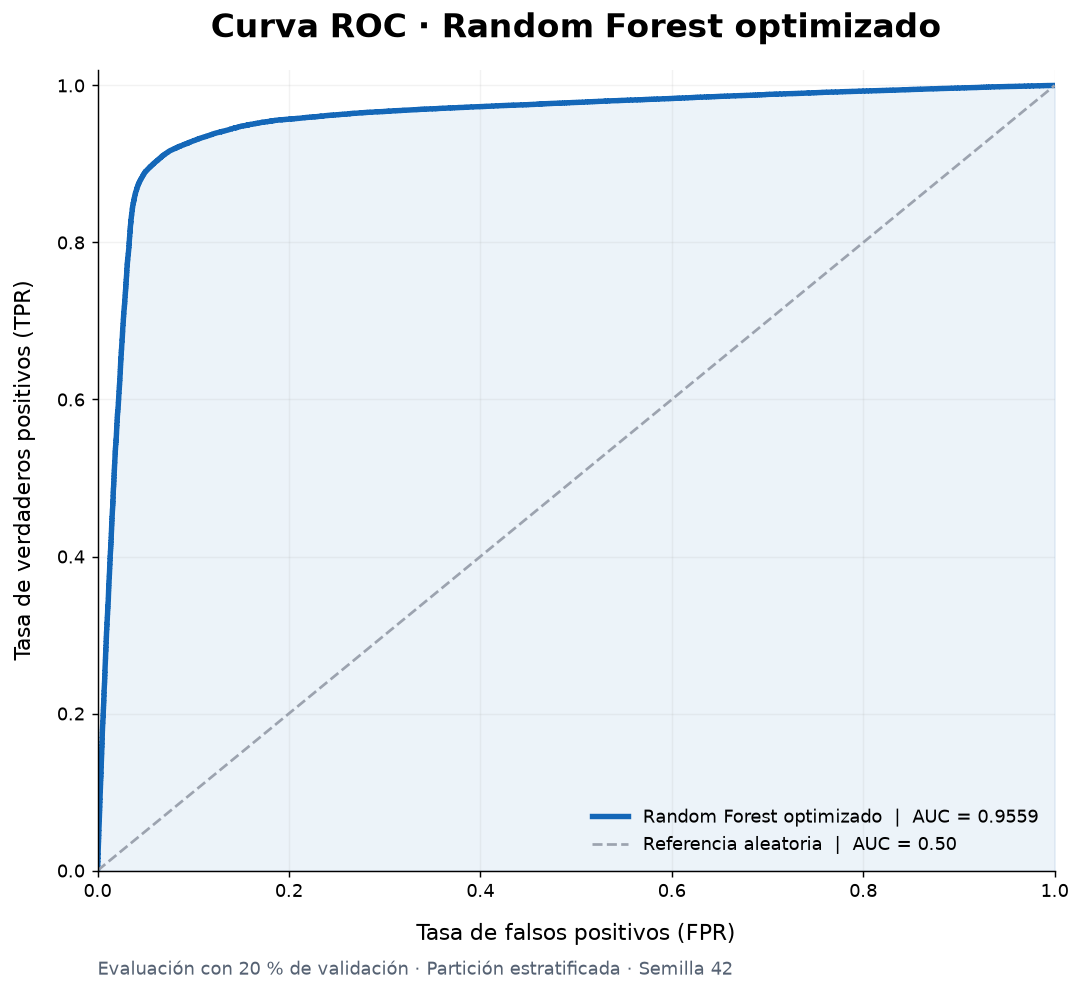

Figura guardada: c:\Users\jrestrepo\OneDrive - Productos Alimenticios Pascual S.A\Escritorio\DATA SCIENCE\Predicting Airline Satisfaction\images\roc_random_forest_optimizado.png


91

In [5]:
fig, ax = plt.subplots(figsize=(9.5, 8), dpi=130)
fig.patch.set_facecolor("white")
ax.set_facecolor("white")

ax.plot(
    fpr, tpr, color="#1467B8", linewidth=3,
    label=f"Random Forest optimizado  |  AUC = {auc_validacion:.4f}",
)
ax.fill_between(fpr, tpr, alpha=0.08, color="#1467B8")
ax.plot(
    [0, 1], [0, 1], color="#9CA3AF", linestyle="--", linewidth=1.5,
    label="Referencia aleatoria  |  AUC = 0.50",
)

ax.set_title("Curva ROC · Random Forest optimizado", fontsize=18, weight="bold", pad=18)
ax.set_xlabel("Tasa de falsos positivos (FPR)", fontsize=12, labelpad=12)
ax.set_ylabel("Tasa de verdaderos positivos (TPR)", fontsize=12, labelpad=12)
ax.set_xlim(0, 1)
ax.set_ylim(0, 1.02)
ax.grid(alpha=0.16, linewidth=0.8)
ax.spines[["top", "right"]].set_visible(False)
ax.legend(loc="lower right", frameon=False, fontsize=10)
ax.text(
    0.0, -0.13,
    "Evaluación con 20 % de validación · Partición estratificada · Semilla 42",
    transform=ax.transAxes, fontsize=10, color="#566273",
)

fig.savefig(
    carpeta_imagenes / "roc_random_forest_optimizado.png",
    dpi=230, bbox_inches="tight", facecolor="white",
)
plt.show()
print("Figura guardada:", carpeta_imagenes / "roc_random_forest_optimizado.png")

# Liberamos memoria antes de entrenar de nuevo con todos los datos.
del modelo_validacion, probabilidades_validacion
gc.collect()

**Interpretación.** Esta curva evalúa la misma configuración optimizada que seleccionamos previamente, usando datos no vistos durante el ajuste. En nuestro experimento original el ROC-AUC de validación fue aproximadamente **0,9559**; el valor que se muestra arriba se calcula de nuevo al ejecutar este notebook. Una ROC-AUC alta indica buena capacidad de discriminación, pero **no equivale a un porcentaje de aciertos** ni garantiza la puntuación de Kaggle.

## 4. Entrenar el modelo final con todos los registros

Después de terminar la evaluación y elegir los hiperparámetros, entrenamos el Pipeline con el **100 % de las filas etiquetadas**. Este es el modelo que utilizaremos para generar probabilidades para `test.csv`.

In [6]:
pipeline_final.fit(X_final, y_final)
print("Modelo definitivo entrenado con", len(X_final), "pasajeros.")
print("Clases del modelo:", pipeline_final.classes_)

Modelo definitivo entrenado con 699635 pasajeros.
Clases del modelo: [False  True]


## 5. Visualización 2 · Un árbol representativo del Random Forest

Un Random Forest está formado por múltiples árboles de decisión; en nuestro modelo son **100 árboles**. Para explicar de forma visual cómo trabajan, mostramos **solo los tres primeros niveles de uno de ellos**.

**Importante:** este gráfico es una muestra de la estructura interna del bosque, no representa por sí solo todas las decisiones ni las predicciones del Random Forest completo. El árbol real puede continuar varios niveles más, hasta la profundidad máxima configurada.

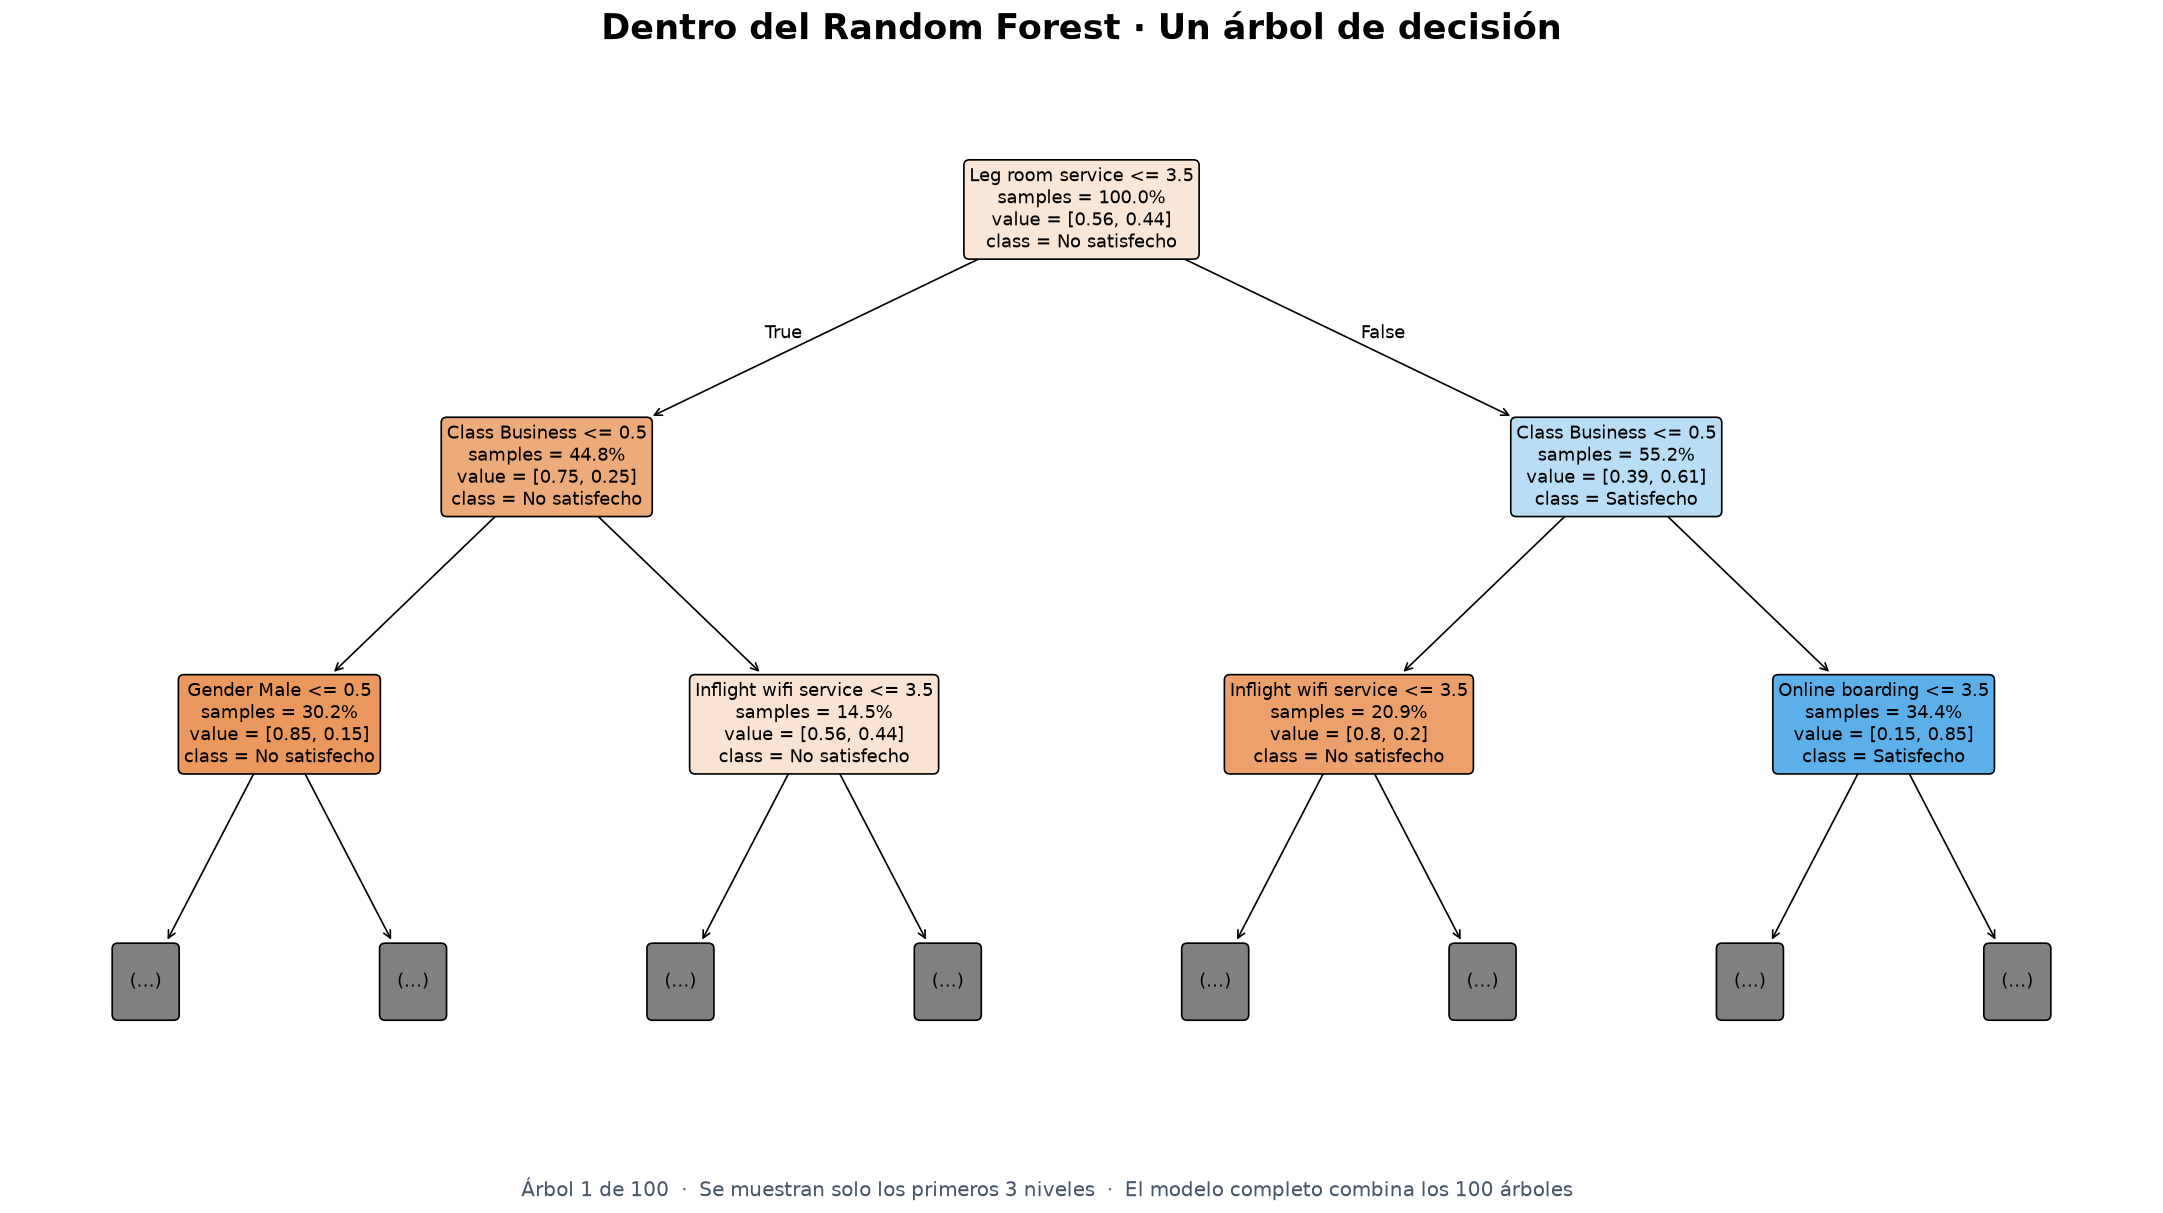

Figura guardada: c:\Users\jrestrepo\OneDrive - Productos Alimenticios Pascual S.A\Escritorio\DATA SCIENCE\Predicting Airline Satisfaction\images\arbol_random_forest_optimizado.png


In [7]:
bosque_entrenado = pipeline_final.named_steps["modelo"]
preprocesador_entrenado = pipeline_final.named_steps["preprocesamiento"]

# Los nombres deben seguir el orden exacto de las columnas transformadas.
nombres_caracteristicas = [
    nombre.split("__", 1)[-1].replace("_", " ")
    for nombre in preprocesador_entrenado.get_feature_names_out()
]

arbol_representativo = bosque_entrenado.estimators_[0]
clases_arbol = ["No satisfecho", "Satisfecho"]

fig, ax = plt.subplots(figsize=(23, 11), dpi=120)
fig.patch.set_facecolor("white")

plot_tree(
    arbol_representativo,
    max_depth=2,                   # 3 niveles visibles (raíz, nivel 1 y nivel 2).
    feature_names=nombres_caracteristicas,
    class_names=clases_arbol,
    filled=True,
    rounded=True,
    proportion=True,
    impurity=False,
    precision=2,
    fontsize=11,
    ax=ax,
)

ax.set_title(
    "Dentro del Random Forest · Un árbol de decisión",
    fontsize=21, weight="bold", pad=25,
)
fig.text(
    0.5, 0.035,
    "Árbol 1 de 100  ·  Se muestran solo los primeros 3 niveles  ·  "
    "El modelo completo combina los 100 árboles",
    ha="center", fontsize=12, color="#475569",
)
fig.subplots_adjust(top=0.88, bottom=0.10)

fig.savefig(
    carpeta_imagenes / "arbol_random_forest_optimizado.png",
    dpi=200, bbox_inches="tight", facecolor="white",
)
plt.show()
print("Figura guardada:", carpeta_imagenes / "arbol_random_forest_optimizado.png")

**Cómo interpretar el árbol:** cada nodo muestra una regla sobre una característica. Según se cumpla o no esa regla, los pasajeros avanzan por distintas ramas. Al final, cada árbol aporta una predicción y el bosque combina la información de los 100 árboles. Aquí recortamos la visualización para que sus reglas principales sean legibles en una publicación; **no recortamos ni modificamos el modelo entrenado**.

## 6. Generar probabilidades para Kaggle

Kaggle espera una columna `satisfaction` con una **probabilidad entre 0 y 1** para cada `id`. Utilizamos `predict_proba()` y seleccionamos la posición correspondiente a la clase positiva (`True`). No calculamos ROC-AUC sobre `test.csv`, porque no conocemos sus etiquetas reales.

In [8]:
probabilidades_test = pipeline_final.predict_proba(X_test)

indice_true_final = np.flatnonzero(pipeline_final.classes_ == True)
assert len(indice_true_final) == 1
predicciones_finales = probabilidades_test[:, indice_true_final[0]]

print("Probabilidades:", probabilidades_test.shape)
print("Predicciones finales:", predicciones_finales.shape)
print("Primeras cinco probabilidades de satisfacción:")
print(np.round(predicciones_finales[:5], 6))

Probabilidades: (299844, 2)
Predicciones finales: (299844,)
Primeras cinco probabilidades de satisfacción:
[0.24534  0.835045 0.83923  0.062098 0.05827 ]


## 7. Crear y validar `submission.csv`

Verificamos que no existan probabilidades faltantes, que los valores estén entre 0 y 1, que no haya identificadores duplicados y que las columnas coincidan con el formato de la competencia.

In [9]:
submission = pd.DataFrame({
    "id": id_test.to_numpy(),
    "satisfaction": predicciones_finales,
})

assert submission.shape == (len(test_final), 2)
assert submission.columns.tolist() == ["id", "satisfaction"]
assert not submission.isna().any().any(), "La entrega contiene valores faltantes."
assert np.isfinite(submission["satisfaction"]).all(), "Hay probabilidades no finitas."
assert submission["satisfaction"].between(0, 1).all(), "Probabilidades fuera de [0, 1]."
assert submission["id"].is_unique, "Hay identificadores duplicados."

ruta_ejemplo = proyecto / "data" / "sample_submission.csv"
if ruta_ejemplo.exists():
    ejemplo = pd.read_csv(ruta_ejemplo, nrows=5)
    assert submission.columns.tolist() == ejemplo.columns.tolist(), (
        "Las columnas no coinciden con sample_submission.csv"
    )

print("Filas para Kaggle:", len(submission))
print("Valores faltantes:", submission.isna().sum().sum())
print("IDs duplicados:", submission["id"].duplicated().sum())
submission.head(10)

Filas para Kaggle: 299844
Valores faltantes: 0
IDs duplicados: 0


,id,satisfaction
0,699635,0.245340
1,699636,0.835045
2,699637,0.839230
3,699638,0.062098
4,699639,0.058270
5,699640,0.963663
6,699641,0.034786
7,699642,0.932045
8,699643,0.925235
9,699644,0.044567


In [10]:
ruta_submission = proyecto / "submission.csv"
submission.to_csv(ruta_submission, index=False)
print("Archivo generado:", ruta_submission)

Archivo generado: c:\Users\jrestrepo\OneDrive - Productos Alimenticios Pascual S.A\Escritorio\DATA SCIENCE\Predicting Airline Satisfaction\submission.csv


## 8. Resultados y archivos para compartir

Seleccionamos Random Forest porque superó a Regresión Logística en la evaluación y la validación cruzada del notebook 03. Tras optimizar cinco combinaciones de hiperparámetros, la configuración ganadora alcanzó un **ROC-AUC promedio CV ≈ 0,9568** y un **ROC-AUC de validación ≈ 0,9559**. Estas cifras describen nuestra evaluación local, no el resultado oculto de Kaggle.

Los archivos generados al ejecutar este notebook se encuentran en:

- **`images/roc_random_forest_optimizado.png`**: curva ROC de validación; útil para presentar el desempeño.
- **`images/arbol_random_forest_optimizado.png`**: vista de un árbol del bosque; útil para explicar cómo funciona el modelo.
- **`submission.csv`**: probabilidades para los pasajeros de `test.csv`.
